# Laboratorio de clasificación 3

---
Nombre: **Alan Jesús Hernández Soto** \
Carrera: **Ingeniería Financiera** \
Materia: **Laboratorio de Aprendizaje Estadístico** \
Tipo de Trabajo: **Laboratorio**

---

|                |   |
:----------------|---|
| **Nombre**     |   |
| **Fecha**      |   |
| **Expediente** |   | 

Una regresión logística simple toma **P** predictores y usa una función no lineal para convertir la respuesta binaria **Y** en probabilidades entre $0$ y $1$.

La visualización de este escenario es puntos separados por una línea recta.

<center><img src="https://wirelesspi.com/wp-content/uploads/2022/08/figure-logistic-regression-decision-boundary-2-570x550.png"></center>

Para casos donde los datos no son linealmente separables usamos el truco del kernel para mapear los datos a un espacio de Hilbert.

Imagina un escenario donde tienes dos predictores $x_1, x_2$ y la salida de estos predictores se comporta de esta manera:

| **$x_1$** | **$x_2$** | Salida |
:-----------|-----------|--------|
| 0         | 0         | 0      |
| 0         | 1         | 1      |
| 1         | 0         | 1      |
| 1         | 1         | 0      |


Imagínalo como el interruptos de luz de un foco en una escalera. Se puede prender y apagar desde arriba y desde abajo.

<center><img src="https://www.researchgate.net/profile/Brian-Spears/publication/322048911/figure/fig4/AS:667820685807618@1536232267250/The-exclusive-or-XOR-function-is-a-nonlinear-function-that-returns-0-when-its-two.png"></center>

¿Cómo podemos separar estos datos usando sólo regresión logística? Sin importar cómo usemos una sola línea, nunca se van a poder separar todos los casos, por lo que tendríamos situaciones donde siempre habría error. 

Solución: ¿Por qué nos estamos limitando a una sola línea?

<center><img src="https://pabloinsente.github.io/assets/post-5/XOR-linear.png"></center>

La regresión logística sola es un método de aprendizaje estadístico convexo. Combinar dos regresiones logísticas para clasificar datos no linealmente separables convierte el problema a uno no convexo. ¿Por qué?

Al entrenar juntas las dos regresiones, sus parámetros se combinan mediante funciones no lineales. La pérdida deja de ser convexa y puede tener mínimos locales y puntos de silla. Usar dos modelos por separado no causa esto automáticamente.

¿Qué significa que una función sea convexa?

Una función es convexa si el segmento entre dos puntos de su gráfica queda por encima o sobre ella. En una función convexa, todo mínimo local también es global.

¿Por qué nos importa que una función sea convexa o no? ¿Qué impacto tiene para los resultados?

La convexidad facilita encontrar un mínimo global. En un problema no convexo, el entrenamiento puede depender de los valores iniciales y llegar a soluciones distintas; por eso conviene fijar la semilla y validar el modelo.

## Ejercicio 1

Utilizaremos el clasificador `MLPClassifier` de la librería `sklearn`.

Entra a la documentación y describe cómo funciona este objeto (qué entradas necesita, qué salidas da, descripción de sus hiperparámetros).

`MLPClassifier` es una red neuronal que ajusta sus pesos por retropropagación para clasificar observaciones.

1. **Entradas:** `X`, con las variables numéricas, y `y`, con las clases. Conviene escalar las variables.
2. **Salidas:** `predict(X)` devuelve clases y `predict_proba(X)` sus probabilidades.
3. **Hiperparámetros:**
   - `hidden_layer_sizes`: neuronas en cada capa oculta.
   - `activation`: función de activación de las capas ocultas.
   - `solver`: optimizador utilizado para entrenar.
   - `alpha`: penalización de pesos grandes para reducir sobreajuste.
   - `batch_size`: observaciones utilizadas en cada lote.
   - `learning_rate_init`: tamaño inicial del paso de aprendizaje.
   - `learning_rate`: forma de ajustar ese paso con SGD.
   - `power_t`: exponente que reduce el paso con `invscaling` en SGD.
   - `max_iter`: máximo de iteraciones de entrenamiento.
   - `shuffle`: mezcla observaciones en cada iteración con SGD o Adam.
   - `random_state`: semilla para reproducir resultados.
   - `tol`: mejora mínima para continuar el entrenamiento.
   - `n_iter_no_change`: iteraciones sin mejora antes de detenerse.
   - `early_stopping`: detiene el entrenamiento si deja de mejorar la exactitud de validación.
   - `validation_fraction`: proporción reservada para la parada anticipada.
   - `momentum`: impulso de las actualizaciones con SGD.
   - `nesterovs_momentum`: activa el impulso de Nesterov con SGD.
   - `beta_1` y `beta_2`: factores de los promedios móviles de Adam.
   - `epsilon`: constante de estabilidad numérica de Adam.
   - `max_fun`: máximo de evaluaciones de la pérdida con L-BFGS.
   - `warm_start`: reutiliza los pesos del entrenamiento anterior.
   - `verbose`: muestra el avance del entrenamiento.


## Ejercicio 2

Utiliza el objeto de perceptrón multicapa para clasificar si un tumor es maligno o benigno con el dataset `Brain Tumor Dataset`. Utiliza un cross-validation de train-test de 70/30. Sigue todos los pasos de EDA y limpieza vistos.

### Carga de Datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Datasets/brain_tumor_dataset.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Patient_ID           20000 non-null  int64  
 1   Age                  20000 non-null  int64  
 2   Gender               20000 non-null  object 
 3   Tumor_Type           20000 non-null  object 
 4   Tumor_Size           20000 non-null  float64
 5   Location             20000 non-null  object 
 6   Histology            20000 non-null  object 
 7   Stage                20000 non-null  object 
 8   Symptom_1            20000 non-null  object 
 9   Symptom_2            20000 non-null  object 
 10  Symptom_3            20000 non-null  object 
 11  Radiation_Treatment  20000 non-null  object 
 12  Surgery_Performed    20000 non-null  object 
 13  Chemotherapy         20000 non-null  object 
 14  Survival_Rate        20000 non-null  float64
 15  Tumor_Growth_Rate    20000 non-null 

### Análisis Exploratorio

,count,mean,std,min,25%,50%,75%,max
Patient_ID,20000.0,10000.500000,5773.647028,1.000000,5000.750000,10000.500000,15000.250000,20000.000000
Age,20000.0,49.433700,17.389296,20.000000,34.000000,49.000000,65.000000,79.000000
Tumor_Size,20000.0,5.236552,2.754359,0.500410,2.836686,5.200675,7.624299,9.999420
Survival_Rate,20000.0,70.131699,17.270834,40.002386,55.224439,70.305066,85.043395,99.998125
Tumor_Growth_Rate,20000.0,1.547701,0.835995,0.100017,0.830433,1.541821,2.262484,2.999835


Tumor_Type
Malignant    10030
Benign        9970
Name: count, dtype: int64

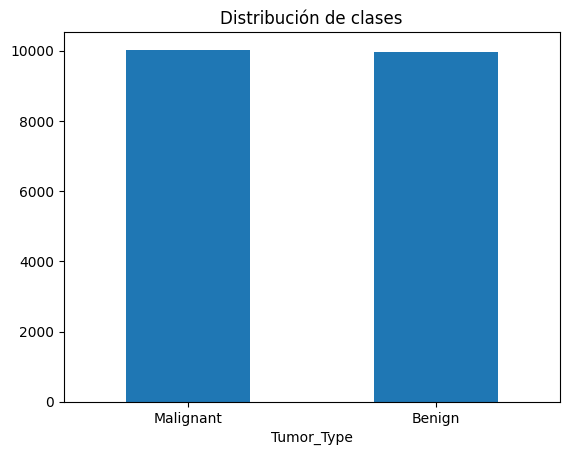

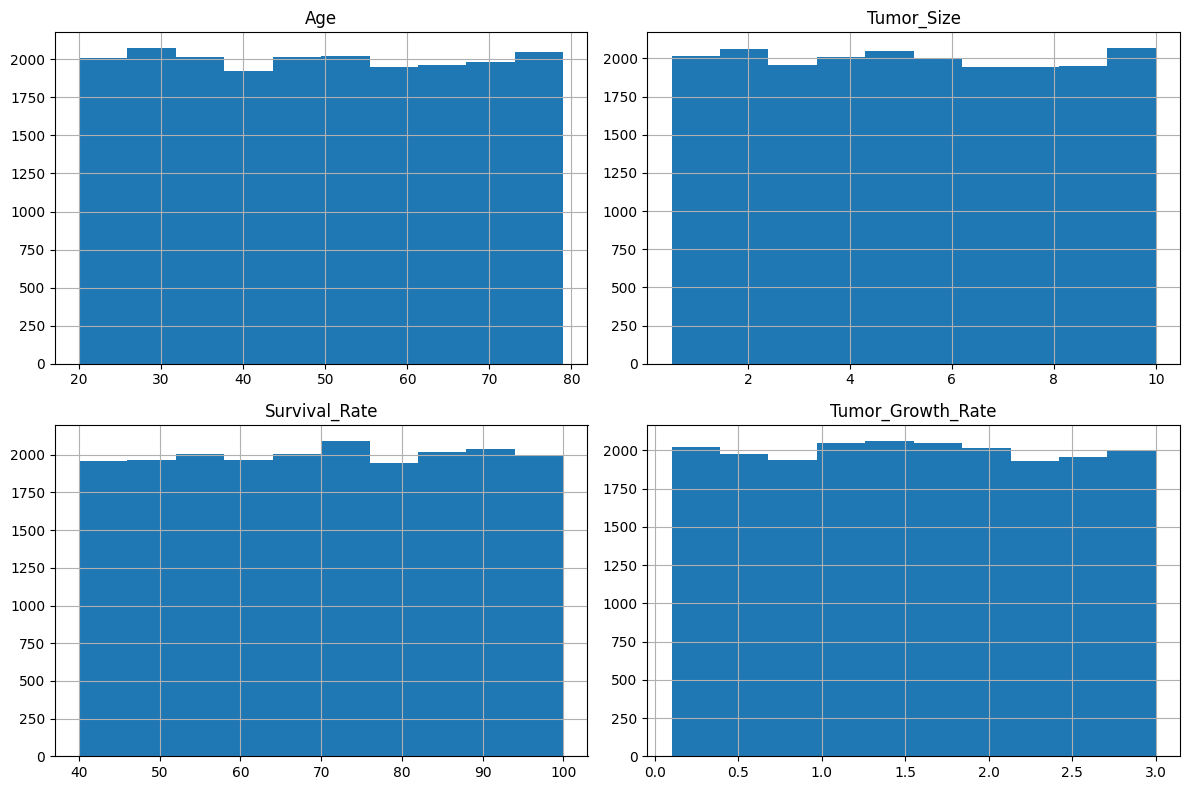

In [2]:
display(df.describe().T)
display(df['Tumor_Type'].value_counts())

df['Tumor_Type'].value_counts().plot.bar(title='Distribución de clases', rot=0)
plt.show()

df[['Age', 'Tumor_Size', 'Survival_Rate', 'Tumor_Growth_Rate']].hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

El dataset tiene 20,000 observaciones: 10,030 tumores malignos y 9,970 benignos. Las clases están equilibradas, los datos asimilan tener una distribución uniforme.

### Limpieza de Datos

**Valores nulos y duplicados**

In [3]:
display(df.isnull().sum())
print('Duplicados:', df.duplicated().sum())
df = df.drop_duplicates()

Patient_ID             0
Age                    0
Gender                 0
Tumor_Type             0
Tumor_Size             0
Location               0
Histology              0
Stage                  0
Symptom_1              0
Symptom_2              0
Symptom_3              0
Radiation_Treatment    0
Surgery_Performed      0
Chemotherapy           0
Survival_Rate          0
Tumor_Growth_Rate      0
Family_History         0
MRI_Result             0
Follow_Up_Required     0
dtype: int64

Duplicados: 0


No hay valores nulos ni duplicados

**Selección de variables**

No es necesario eliminar predictores. Se conservan todas las variables, excepto `Patient_ID`, porque solo identifica al paciente. `Tumor_Type` se utiliza como variable objetivo.

In [4]:
X = df.drop(columns=['Tumor_Type', 'Patient_ID'])
Y = df['Tumor_Type'].map({'Benign': 0, 'Malignant': 1})

display(X.select_dtypes(include='number').corr())

,Age,Tumor_Size,Survival_Rate,Tumor_Growth_Rate
Age,1.000000,-0.014385,-0.014825,-0.009853
Tumor_Size,-0.014385,1.000000,0.003295,0.004347
Survival_Rate,-0.014825,0.003295,1.000000,-0.006825
Tumor_Growth_Rate,-0.009853,0.004347,-0.006825,1.000000


### División de Datos

Se utiliza 70% para entrenamiento y 30% para prueba, conservando la proporción de clases. No se hacen divisiones adicionales.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.30, stratify=Y, random_state=42
)

### Ingeniería de Características

Se codifican las variables categóricas con dummies y se escalan las variables. La codificación y el escalado se ajustan con los datos de entrenamiento.

In [6]:
from sklearn.preprocessing import StandardScaler

X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Clasificación

In [7]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix

mlp = MLPClassifier(max_iter=500, random_state=42)
mlp.fit(X_train_s, Y_train)
Y_pred = mlp.predict(X_test_s)
recall_base = recall_score(Y_test, Y_pred)

results = pd.DataFrame({
    'Recall': [recall_base],
    'Precisión': [precision_score(Y_test, Y_pred, zero_division=0)],
    'F1': [f1_score(Y_test, Y_pred, zero_division=0)]
}, index=['Modelo inicial: prueba'])
display(results.round(4))

,Recall,Precisión,F1
Modelo inicial: prueba,0.4772,0.5021,0.4894


¿Qué métrico crees que sea mejor para este ejercicio? Escoge los 3 métricos que crees más apropiados para esta predicción, argumenta en pro y en contra del top 3. Elige uno para optimizar (justifica tu respuesta).

### Elección de Métricas

1. **Recall:** detecta más malignos, pero puede aumentar las falsas alarmas.
2. **F1:** equilibra precisión y recall, pero no considera los verdaderos negativos.
3. **Precisión:** reduce falsas alarmas entre los positivos, pero puede dejar malignos sin detectar.

Se optimiza **recall** para reducir falsos negativos. También se revisan precisión y F1, porque clasificar todo como maligno daría recall de 1 sin distinguir las clases.

## Ejercicio 3

Modifica los hiperparámetros para elevar el métrico elegido. Intenta con 10 sets de hiperparámetros distintos. Crea una tabla que muestre los resultados.

### Mejora y Comparación de Modelos

Las diez configuraciones se entrenan con el mismo 70% y se comparan sobre el mismo 30%. Como ese 30% se utiliza para elegir el modelo, los resultados son comparativos y no constituyen una evaluación independiente.

In [8]:
configuraciones = [
    ((16,), 'relu', 0.0001, 0.001),
    ((32,), 'relu', 0.0001, 0.001),
    ((64,), 'relu', 0.0001, 0.001),
    ((100,), 'relu', 0.0001, 0.001),
    ((32, 16), 'relu', 0.0001, 0.001),
    ((64, 32), 'relu', 0.001, 0.001),
    ((32,), 'tanh', 0.0001, 0.001),
    ((64,), 'tanh', 0.001, 0.001),
    ((32, 16), 'tanh', 0.01, 0.001),
    ((64, 32), 'relu', 0.01, 0.0005)
]

resultados = []
modelos = []
for capas, activacion, alpha, tasa in configuraciones:
    mlp = MLPClassifier(hidden_layer_sizes=capas, activation=activacion,
                        alpha=alpha, learning_rate_init=tasa, max_iter=500,
                        random_state=42)
    mlp.fit(X_train_s, Y_train)
    modelos.append(mlp)
    Y_pred = mlp.predict(X_test_s)
    resultados.append([capas, activacion, alpha, tasa,
                       recall_score(Y_test, Y_pred),
                       precision_score(Y_test, Y_pred, zero_division=0),
                       f1_score(Y_test, Y_pred, zero_division=0)])

tabla = pd.DataFrame(resultados, columns=['Capas', 'Activación', 'Alpha', 'Tasa',
                                         'Recall', 'Precisión', 'F1'])
tabla = tabla.sort_values('Recall', ascending=False)
display(tabla.round(4))

mejor = tabla.iloc[0]
mlp = modelos[tabla.index[0]]
print(f"Mejora de recall en prueba: {mejor['Recall'] - recall_base:.4f}")

c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't 

,Capas,Activación,Alpha,Tasa,Recall,Precisión,F1
5,"(64, 32)",relu,0.0010,0.0010,0.5503,0.5066,0.5276
9,"(64, 32)",relu,0.0100,0.0005,0.5354,0.5106,0.5227
2,"(64,)",relu,0.0001,0.0010,0.5317,0.5008,0.5158
0,"(16,)",relu,0.0001,0.0010,0.5155,0.5070,0.5112
7,"(64,)",tanh,0.0010,0.0010,0.5078,0.5041,0.5060
8,"(32, 16)",tanh,0.0100,0.0010,0.5055,0.5046,0.5051
4,"(32, 16)",relu,0.0001,0.0010,0.4978,0.4993,0.4986
6,"(32,)",tanh,0.0001,0.0010,0.4948,0.4939,0.4944
3,"(100,)",relu,0.0001,0.0010,0.4772,0.5021,0.4894
1,"(32,)",relu,0.0001,0.0010,0.4766,0.5026,0.4893


Mejora de recall en prueba: 0.0731


### Resultados del Mejor Modelo

Se muestran las métricas y la matriz de confusión de la configuración con mayor recall en el 30% de prueba.

In [9]:
Y_pred = mlp.predict(X_test_s)

results = pd.DataFrame({
    'Recall': [recall_score(Y_test, Y_pred)],
    'Precisión': [precision_score(Y_test, Y_pred, zero_division=0)],
    'F1': [f1_score(Y_test, Y_pred, zero_division=0)]
}, index=['Mejor modelo: prueba'])
display(results.round(4))

display(pd.DataFrame(confusion_matrix(Y_test, Y_pred),
                     index=['Real benigno', 'Real maligno'],
                     columns=['Predicho benigno', 'Predicho maligno']))

,Recall,Precisión,F1
Mejor modelo: prueba,0.5503,0.5066,0.5276


,Predicho benigno,Predicho maligno
Real benigno,1378,1613
Real maligno,1353,1656


### Conclusión

Con la división 70/30, el recall del modelo inicial fue 0.477 y el de la mejor configuración fue 0.550. Esta obtuvo precisión de 0.507 y F1 de 0.528. La comparación usa el mismo conjunto de prueba para las diez configuraciones.